# Evolution of star clusters in arbitrary tidal fields
Florent Renaud, Mark Gieles, Christian Boily. 2011
doi:10.1111/j.1365-2966.2011.19531.x

## Goal

- play with the results of the paper 
- make some jacobi surfaces 
- make an animation of a surface in the cluster frame 
- make an animation of the football flying through space 

In [1]:
import numpy, matplotlib.pyplot as plt, agama, os
agama.setUnits(mass=1, length=1, velocity=1)
import sympy as sp 
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from skimage import measure
from skimage.draw import ellipsoid
from astropy import constants as cnst 
from astropy import units as u 
from scipy.optimize import root

## The equations

Hello, my goal is to write a code to compute the jacobii surface of a cluster in an arbitrary potential numerically. I'm following this paper where they first derive the acceleration of a particle in the non-inertial reference frame centered on the star cluster: 

$$ \frac{d^2 \mathbf{r}}{dt^2} = -\nabla \phi_c(\mathbf{r}) + \mathbf{T}_t (\mathbf{r})\cdot\mathbf{r} - \Omega \times (\Omega \times \mathbf{r}) - \frac{d\Omega}{dt}\times \mathbf{r} - 2\mathbf{\Omega}\times\frac{d\mathbf{r}}{dt}$$

First. I think this paper has a mistake? if we're in the frame centered on teh cluster, and $\mathbf{r}$ is the position of a particle relative to the cluster's center of mass... Then, $\mathbf{r}$ cannot also be the argument for the tidal tensor, correct? the tidal tensor's argument is the position of the globular cluster. Because, we linearlize the galaxy's gravitational field about the position of the cluster... $F_{\mathrm{gal}} \approx \mathbf{T}(\mathbf{r}_\mathrm{gc})\cdot d\mathbf{r}$ where $d\mathbf{r} = r_{\mathrm{star}}-\mathbf{r}_\mathrm{gc}$

My goal is to write a code that can numerically find the jacobi surface for any cluster potential, any galactic potential, and return it's orientation. I'm confused on how to do this. Next, the paper looks at the effective potential for the centrigual froce. 

$$\phi(\mathbf{r})_f = \frac{1}{2} (\mathbf{r}\cdot\mathbf{\Omega})^2 - \frac{1}{2}\mathbf{\Omega}^2\mathbf{r}^2$$

Okay? and then they define the effective tidal tensor as: 

$$T^{ij}_e(\mathbf{r})= T^{ij}_{t}(\mathbf{r}) + \left(-\frac{\partial^2 \phi_f }{\partial x^i\partial x^j}\right)$$

So, I tried doing this by hand to see what the tensor looks like and, I don't think it's worth my time? Is this bringing my anycloser to visluaizing the jacobi surfaces? 



In [2]:
def getOmega(posvel):
    return numpy.linalg.cross(posvel[0:3],posvel[3:6]) / numpy.linalg.norm(posvel[0:3])**2

def construct_tidal_tensor(pot, posvel):
    # build the tidal tensor
    dFxdx,dFydy,dFzdz,dFxdy,dFydz,dFzdx=pot.eval(posvel[0:3],der=True).T
    dFydx       =   dFxdy
    dFxdz       =   dFzdx
    dFzdy       =   dFydz
    column1     =   numpy.array([dFxdx, dFydx, dFzdx])
    column2     =   numpy.array([dFxdy, dFydy, dFzdy])
    column3     =   numpy.array([dFxdz, dFydz, dFzdz])
    tidalTensor =   numpy.column_stack([column1,column2,column3])
    return tidalTensor

def effective_acceleration(r, pot_cluster, H, Omega):
    A = H - (
        numpy.dot(Omega, Omega) * numpy.eye(3)
        - numpy.outer(Omega, Omega)
    )
    a_cluster = numpy.asarray(
        pot_cluster.force(r[None, :])
    ).reshape(-1, 3)[0]
    return a_cluster - A @ r

def effective_potential(r, pot_cluster, H, omega):
    r = numpy.atleast_2d(r)

    phi_cluster = pot_cluster.eval(r, pot=True)

    A = H - (
        numpy.dot(omega, omega) * numpy.eye(3)
        - numpy.outer(omega, omega)
    )

    phi_tidal = 0.5 * numpy.sum((r @ A) * r, axis=1)

    return phi_cluster + phi_tidal

In [3]:
agama.setUnits(mass=1, length=1, velocity=1)

In [4]:
# initialize our potential 
potential   =   "McMillan17.ini"
path        =   agama.__path__[0] + "/data/" + "McMillan17.ini"
pot         =   agama.Potential(path)
massCluster =   1e5
pot_cluster =   agama.Potential(type="plummer", mass=massCluster, scaleRadius=5e-3)

In [5]:
# pick a cluster orbit
rGC     =   numpy.array([1,2,0])
vcirc   =   numpy.sqrt(-numpy.dot(pot.force(rGC),rGC))
vel     =   numpy.array([0,-vcirc,0])
posvel  =   numpy.concatenate((rGC,vel))
traj    =   agama.orbit(ic=posvel,potential=pot,time=1,dtype=object)

In [6]:
posvelGC    =   traj(0)
Omega       =   getOmega(posvelGC)
tidalTensor =   construct_tidal_tensor(pot,posvel)

In [7]:
effective_tensor = -tidalTensor - numpy.dot(Omega, Omega) * numpy.eye(3) + numpy.outer(Omega, Omega)

H = -tidalTensor

A = H - (
    numpy.dot(Omega, Omega) * numpy.eye(3)
    - numpy.outer(Omega, Omega)
)


In [8]:
unitG = (u.km/u.s)**2 * (u.kpc/u.Msun )
G=cnst.G.to(unitG).value
# get the approximate solution
eigenvalues, eigenvectors = numpy.linalg.eigh(A)

i = numpy.argmin(eigenvalues)
lam = eigenvalues[i]

if lam >= 0:
    raise ValueError("No negative eigenvalue: no point-mass tidal estimate.")

r_guess = (G * massCluster / abs(lam))**(1/3)
direction = eigenvectors[:, i]


In [9]:
result = root(
    lambda r: effective_acceleration(
        r, pot_cluster, H, Omega
    ),
    r_guess*direction
)

if not result.success:
    raise RuntimeError(result.message)

r_L1 = result.x
print("3D L1 candidate:", r_L1)
print("Residual acceleration:",
      numpy.linalg.norm(
          effective_acceleration(
              r_L1, pot_cluster, H, Omega
          )
      ))

3D L1 candidate: [0.01785388 0.03570775 0.        ]
Residual acceleration: 3.1776437161565096e-14


In [10]:
# Evaluate the potential at the cluster centre and L1

E0 = effective_potential(
    numpy.zeros(3), pot_cluster, H, Omega
)[0]

EL1 = effective_potential(
    r_L1, pot_cluster, H, Omega
)[0]

key_levels = numpy.array([E0,EL1])
levels = numpy.linspace(key_levels.min(), key_levels.max(), 30)
levels = numpy.sort(levels)[::-1]

# Set the plotting extent using the L1 distance
lims = 2.0 * numpy.linalg.norm(r_L1)
npoints = 500

xs = numpy.linspace(-lims, lims, npoints)
ys = numpy.linspace(-lims, lims, npoints)

XS, YS = numpy.meshgrid(xs, ys)
pos = numpy.column_stack((
    XS.ravel(),
    YS.ravel(),
    numpy.zeros(XS.size)
))

phi_eff = effective_potential(pos, pot_cluster, H, Omega)
phi_eff = phi_eff.reshape(XS.shape)


In [11]:
levels=numpy.unique(levels)

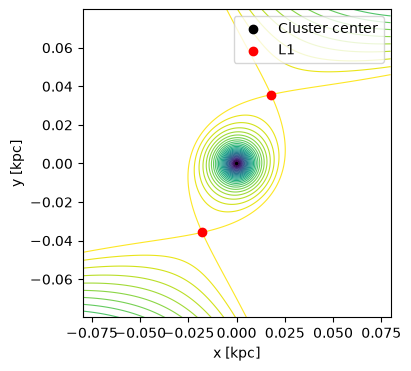

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))

# Background contours
ax.contour(XS, YS, phi_eff, levels=levels, linewidths=0.8)

# Mark the cluster centre and L1
ax.scatter(0, 0, color="black", label="Cluster center")
ax.scatter(r_L1[0], r_L1[1], color="red", label="L1",zorder=10)
ax.scatter(-r_L1[0], -r_L1[1], color="red",zorder=10)
ax.set_xlabel("x [kpc]")
ax.set_ylabel("y [kpc]")
ax.set_aspect("equal")
ax.legend()
ax.set(aspect="equal")
plt.show()

now try the marching cubes


In [20]:
numpy.linalg.norm(r_L1)

np.float64(0.0399224829497912)

In [57]:
dist=numpy.linalg.norm(r_L1)
npoints = 15
xs = numpy.linspace(-dist,dist,npoints)
XS,YS,ZS=numpy.meshgrid(xs,xs,xs)
points = numpy.column_stack((XS.flatten(),YS.flatten(),ZS.flatten()))
pot_eff_3D=effective_potential(points,pot_cluster,H,Omega)
pot_eff_3D=numpy.reshape(pot_eff_3D,XS.shape)

In [58]:
from skimage import measure
verts, faces, normals, values = measure.marching_cubes(pot_eff_3D,EL1)

[None]

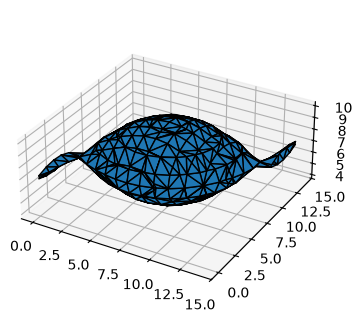

In [61]:
fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(111, projection='3d')

# Fancy indexing: `verts[faces]` to generate a collection of triangles
mesh = Poly3DCollection(verts[faces])
mesh.set_edgecolor('k')
ax.add_collection3d(mesh)


ax.set(aspect="equal")